# Extracting and Visualizing Stock Data
### Tesla (TSLA) & GameStop (GME)

**Project type:** Data Collection, Web Scraping, Data Cleaning & Visualization  
**Tools:** Python, yfinance, Pandas, Requests, BeautifulSoup, Matplotlib  
**Data sources:** Yahoo Finance and IBM Skills Network sample revenue tables

---

## 1. Project Overview

The goal of this project is to collect historical stock-price data for Tesla and GameStop, extract their annual revenue data from web pages, clean the datasets, and visualize stock prices alongside revenue.

### Business questions
- How have Tesla's and GameStop's stock prices changed over time?
- How has each company's annual revenue changed?
- What can we observe when stock-price trends and revenue trends are viewed together?

### Project workflow
1. Import the required libraries.
2. Collect historical stock data with `yfinance`.
3. Scrape annual revenue tables from web pages.
4. Clean and prepare the data.
5. Display the latest/oldest available revenue records.
6. Visualize stock prices and revenue.

> **Data coverage note:** The sample revenue pages used in this assignment contain annual revenue data only up to 2021. The stock-price data from Yahoo Finance can extend beyond 2021. The graph function below preserves the assignment's original comparison cutoff (June 14, 2021 for stock prices and April 30, 2021 for revenue).

## 2. Install dependencies

Run this cell only if the required libraries are not already installed in your Python environment. In a local environment, you can also install them from a terminal.

In [156]:
# Install the libraries required for data collection and analysis.
%pip install yfinance beautifulsoup4 pandas requests matplotlib lxml

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 3. Import libraries

- `yfinance`: downloads historical stock-market data.
- `pandas`: stores, cleans, and analyzes tabular data.
- `requests`: downloads the web pages containing revenue tables.
- `BeautifulSoup`: parses HTML content.
- `StringIO`: allows Pandas to read HTML text as a file-like object.
- `matplotlib`: creates the charts.

In [157]:
import yfinance as yf
import pandas as pd
import requests
import matplotlib.pyplot as plt

from bs4 import BeautifulSoup
from io import StringIO

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

## 4. Define a reusable visualization function

The `make_graph()` function creates two charts:
- Historical closing share price.
- Annual company revenue.

The function filters the data to the dates specified in the original assignment so the two companies can be compared over the same historical period.

In [158]:
def make_graph(stock_data, revenue_data, stock_name):
    # Keep stock-price observations up to June 14, 2021.
    stock_data_filtered = stock_data.loc[
        stock_data["Date"] <= "2021-06-14"
    ].copy()

    # Keep revenue observations up to April 30, 2021.
    revenue_data_filtered = revenue_data.loc[
        revenue_data["Date"] <= "2021-04-30"
    ].copy()

    # Create two vertically stacked charts with a shared date axis.
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

    # Plot the historical closing share price.
    axes[0].plot(
        pd.to_datetime(stock_data_filtered["Date"]),
        pd.to_numeric(stock_data_filtered["Close"], errors="coerce"),
        label="Closing Share Price"
    )
    axes[0].set_title(f"{stock_name} - Historical Share Price")
    axes[0].set_ylabel("Share Price (USD)")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    # Plot annual revenue.
    axes[1].plot(
        pd.to_datetime(revenue_data_filtered["Date"]),
        pd.to_numeric(revenue_data_filtered["Revenue"], errors="coerce"),
        marker="o",
        label="Annual Revenue"
    )
    axes[1].set_title(f"{stock_name} - Historical Annual Revenue")
    axes[1].set_ylabel("Revenue (USD millions)")
    axes[1].set_xlabel("Date")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    # Improve spacing and display the charts.
    plt.tight_layout()
    plt.show()

# Part A — Tesla (TSLA)

## 5. Collect Tesla historical stock data

Yahoo Finance identifies Tesla with the ticker symbol `TSLA`. We create a ticker object and use `history(period="max")` to request the maximum available historical period.

If Yahoo Finance temporarily fails to respond, rerun the cell later and check your internet connection.

### Create a Yahoo Finance ticker object for Tesla.

In [159]:
tesla = yf.Ticker("TSLA")

### Download the maximum available historical stock-price data.

In [160]:
tesla_data = tesla.history(period="max")

### Convert the Date index into a regular column.

In [161]:
tesla_data.reset_index(inplace=True)


C:\Users\عبد الله\AppData\Local\Temp\ipykernel_46112\4108378121.py:1: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  tesla_data.reset_index(inplace=True)


### Display the first five records.

In [162]:
tesla_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


## 6. Extract Tesla annual revenue using web scraping

We download the IBM Skills Network sample page that contains Tesla's annual revenue table. `requests` retrieves the HTML, `BeautifulSoup` parses the page, and `pandas.read_html()` extracts the table.

In [163]:
# URL containing the Tesla annual revenue table.
tesla_url = (
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
    "IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"
)

# Download the web page and check that the request succeeded.
tesla_response = requests.get(tesla_url, timeout=30)
tesla_response.raise_for_status()

# Parse the HTML page.
tesla_soup = BeautifulSoup(tesla_response.text, "html.parser")

# Extract the first HTML table into a DataFrame.
tesla_revenue = pd.read_html(StringIO(tesla_response.text))[0]

# Rename the columns to consistent, clear names.
tesla_revenue.columns = ["Date", "Revenue"]

# Convert the year values into dates.
tesla_revenue["Date"] = pd.to_datetime(
    tesla_revenue["Date"].astype(str),
    format="%Y",
    errors="coerce"
)

# Display the extracted table.
tesla_revenue.head()

,Date,Revenue
0,2021-01-01,"$53,823"
1,2020-01-01,"$31,536"
2,2019-01-01,"$24,578"
3,2018-01-01,"$21,461"
4,2017-01-01,"$11,759"


## 7. Clean Tesla revenue data

The revenue values include dollar signs and commas. We remove these characters, convert revenue to numeric values, and remove missing or invalid records.

**Important:** The revenue values in this sample table are expressed in USD millions.

### Remove dollar signs and thousands separators from revenue values.

In [164]:
tesla_revenue["Revenue"] = tesla_revenue['Revenue'].str.replace(',|\$',"",regex=True)

<>:1: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:1: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
C:\Users\عبد الله\AppData\Local\Temp\ipykernel_46112\3152827612.py:1: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
  tesla_revenue["Revenue"] = tesla_revenue['Revenue'].str.replace(',|\$',"",regex=True)


### Remove rows with missing dates or revenue.

In [165]:
esla_revenue = tesla_revenue.dropna(
    subset=["Date", "Revenue"]
).copy()

### Display the final five rows in the table's current order.

In [166]:
tesla_revenue.tail()

,Date,Revenue
8,2013-01-01,2013
9,2012-01-01,413
10,2011-01-01,204
11,2010-01-01,117
12,2009-01-01,112


### Tesla revenue output — how to interpret `tail()`

The source table is ordered from the newest year to the oldest year. Therefore, `tail()` displays the last rows in that existing order, which are the oldest years (for example, 2009). This does **not** mean the data collection failed.

To display the newest five years instead, use `head()` or sort the table by date.

In [167]:
# Optional: display the five most recent years in chronological order.
tesla_revenue.sort_values("Date", ascending=False).head()

,Date,Revenue
0,2021-01-01,53823
1,2020-01-01,31536
2,2019-01-01,24578
3,2018-01-01,21461
4,2017-01-01,11759


## 8. Visualize Tesla stock price and revenue

The function displays Tesla's historical closing share price and annual revenue in separate charts.

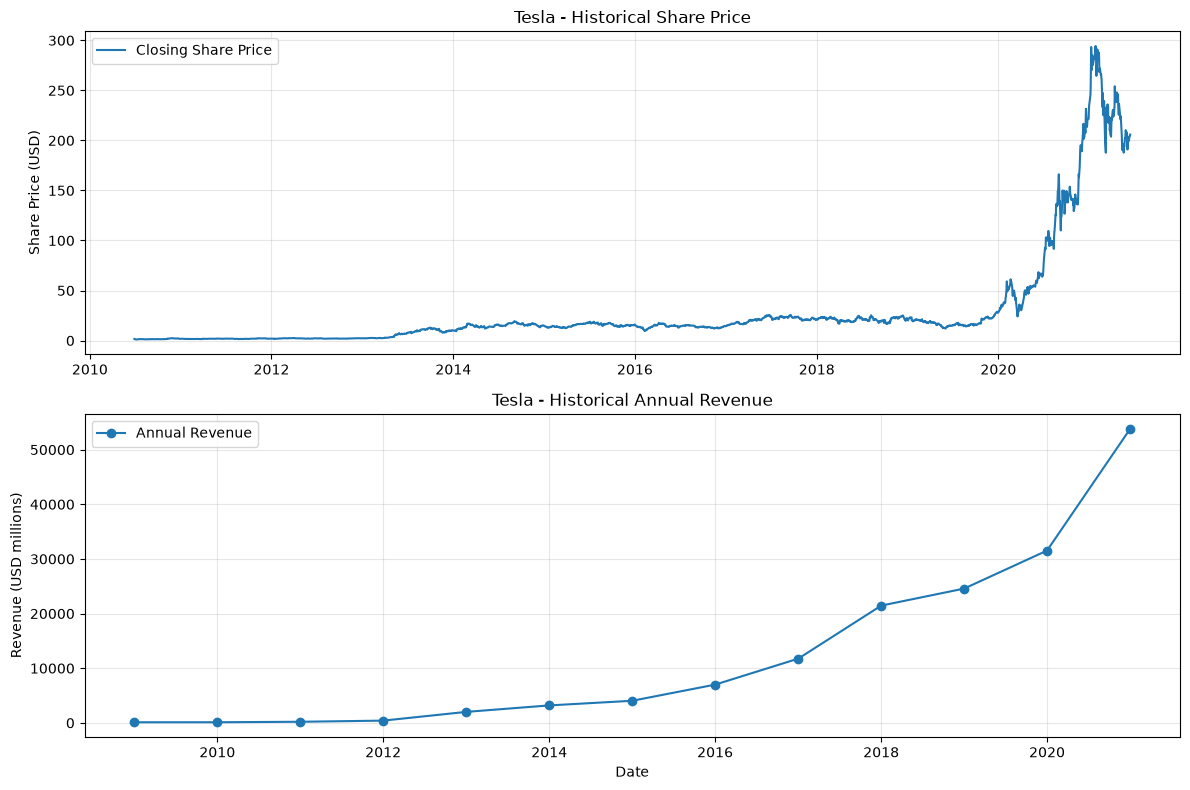

In [168]:
# Create the Tesla stock-price and revenue charts.
make_graph(tesla_data, tesla_revenue, "Tesla")

# Part B — GameStop (GME)

## 9. Collect GameStop historical stock data

GameStop's ticker symbol is `GME`. We use the same `yfinance` workflow as for Tesla to download historical stock data.

### Create a Yahoo Finance ticker object for GameStop.

In [169]:
gme = yf.Ticker("GME")

### Download the maximum available historical stock-price data.

In [170]:
gme_data = gme.history(period="max")

### Convert the Date index into a regular column.

In [171]:
gme_data.reset_index(inplace=True)


C:\Users\عبد الله\AppData\Local\Temp\ipykernel_46112\2275580944.py:1: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  gme_data.reset_index(inplace=True)


### Display the first five records.

In [172]:
gme_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620128,1.693350,1.603296,1.691666,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716074,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683251,1.687459,1.658002,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615920,1.662210,1.603296,1.662210,6892800,0.0,0.0


## 10. Extract GameStop annual revenue using web scraping

We download the GameStop sample revenue page, parse its HTML, and extract the first table into a Pandas DataFrame.

In [173]:
# URL containing the GameStop annual revenue table.
gme_url = (
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
    "IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html"
)

# Download the web page and check that the request succeeded.
gme_response = requests.get(gme_url, timeout=30)
gme_response.raise_for_status()

# Parse the HTML page.
gme_soup = BeautifulSoup(gme_response.text, "html.parser")

# Extract the first HTML table into a DataFrame.
gme_revenue = pd.read_html(StringIO(gme_response.text))[0]

# Rename the columns.
gme_revenue.columns = ["Date", "Revenue"]

# Convert year values into dates.
gme_revenue["Date"] = pd.to_datetime(
    gme_revenue["Date"].astype(str),
    format="%Y",
    errors="coerce"
)

# Display the extracted table.
gme_revenue.head()

,Date,Revenue
0,2020-01-01,"$6,466"
1,2019-01-01,"$8,285"
2,2018-01-01,"$8,547"
3,2017-01-01,"$7,965"
4,2016-01-01,"$9,364"


## 11. Clean GameStop revenue data

We apply the same cleaning steps used for Tesla. Make sure every operation in this section targets `gme_revenue`, not `tesla_revenue`.

### Remove dollar signs and commas from GameStop revenue values.

In [174]:
gme_revenue["Revenue"] = gme_revenue['Revenue'].str.replace(',|\$',"",regex=True)




<>:1: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:1: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
C:\Users\عبد الله\AppData\Local\Temp\ipykernel_46112\3854211337.py:1: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
  gme_revenue["Revenue"] = gme_revenue['Revenue'].str.replace(',|\$',"",regex=True)


### Remove rows with missing dates or revenue.

In [175]:
gme_revenue = gme_revenue.dropna(
    subset=["Date", "Revenue"]
).copy()

# Display the final five rows in the table's current order.

In [176]:
gme_revenue.tail()

,Date,Revenue
11,2009-01-01,8806
12,2008-01-01,7094
13,2007-01-01,5319
14,2006-01-01,3092
15,2005-01-01,1843


### GameStop revenue output — how to interpret `tail()`

As with Tesla, the sample source table is ordered from newest to oldest. `tail()` therefore displays the oldest records. Use the next cell to display the most recent five years.

In [177]:
# Optional: display the five most recent GameStop revenue records.
gme_revenue.sort_values("Date", ascending=False).head()
gme_revenue

,Date,Revenue
0,2020-01-01,6466
1,2019-01-01,8285
2,2018-01-01,8547
3,2017-01-01,7965
4,2016-01-01,9364
5,2015-01-01,9296
6,2014-01-01,9040
7,2013-01-01,8887
8,2012-01-01,9551
9,2011-01-01,9474


## 12. Visualize GameStop stock price and revenue

We reuse the same function to visualize GameStop's historical share price and annual revenue.

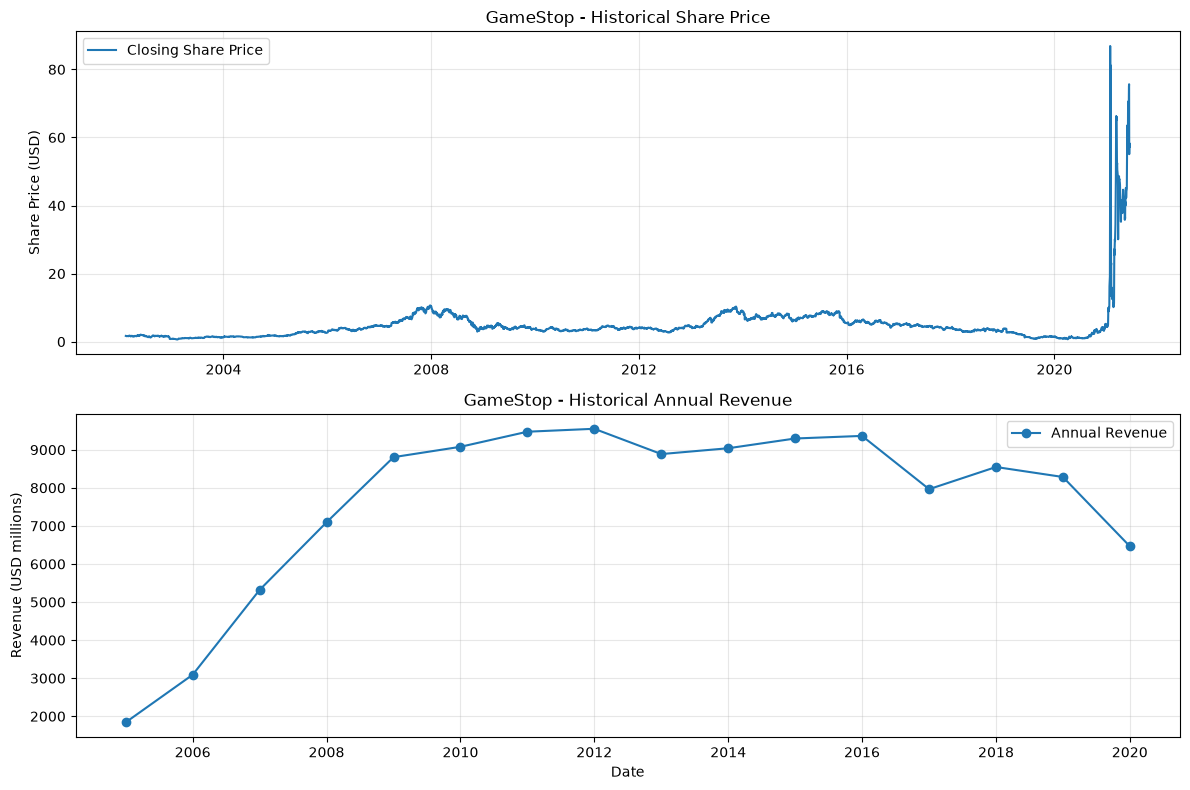

In [178]:
# Create the GameStop stock-price and revenue charts.
make_graph(gme_data, gme_revenue, "GameStop")

# 13. Project Summary

In this project, we practiced a complete introductory data-analysis workflow:

- **Data extraction:** downloaded historical stock data with `yfinance`.
- **Web scraping:** retrieved annual revenue tables from HTML pages.
- **Data cleaning:** removed currency symbols and commas, converted values to numeric types, and handled missing records.
- **Data preparation:** converted year values into dates and organized the data into Pandas DataFrames.
- **Data visualization:** used Matplotlib to compare historical share prices and annual revenue.

## 14. Key learning outcomes

After completing this project, you should be able to:
1. Retrieve stock-market data using a ticker symbol.
2. download and parse HTML content.
3. extract web tables with Pandas.
4. clean text-based financial values.
5. create reusable Python functions for visualization.
6. explain the difference between stock-price data and annual revenue data.

## 15. Notes and limitations

- The revenue data comes from the static sample pages supplied for this learning project; it is not a live financial feed.
- Stock-price history and revenue data have different date coverage.
- The charts are limited to the historical dates specified in the assignment's graphing function.
- A stock-price trend and a revenue trend are different measures and should not be treated as proof that one caused the other.

---
**Project status:** Completed — data extraction, cleaning, and visualization for Tesla and GameStop.

---
### Auther
* **Name :**     Abdullah Omar Bawazir
* **Email :**     engabdullahomarbawazir@gmail.com
* **Github :**     https://github.com/engabdullahomarbawazir
* **LinkedIn :**     https://www.linkedin.com/in/abdullah-bawazir-87277144b?utm_source=share_via&utm_content=profile&utm_medium=member_android
